In [1]:
import numpy as np
from scipy.sparse import csr_matrix
import scipy.linalg as la
import matplotlib.pyplot as plt

In [2]:
from src import pxp, dynamics, benchmarks, scoring, evaluation, observables

In [ ]:
# Checking Hermiticity

L = 8
state = pxp.basisStates(L)
indices = pxp.build_constrained_basis(L)
H0 = pxp.build_deformed_pxp_hamiltonian(state)

operators = {
    "PXP": H0,
    "lambda2": pxp.build_deformed_pxp_hamiltonian(state, lambda2=1) - H0,
    "lambda3": pxp.build_deformed_pxp_hamiltonian(state, lambda3=1) - H0,
    "lambda22": pxp.build_deformed_pxp_hamiltonian(state, lambda22=1) - H0,
    "delta": pxp.build_deformed_pxp_hamiltonian(state, delta=1) - H0,
    "V": pxp.build_deformed_pxp_hamiltonian(state, V=1) - H0
}

projected = {}

for name, operator in operators.items():
    projected[name] = operator[indices, :][:, indices]

    hermiticity_error = operator - operator.getH()
    projected_error = projected[name] - projected[name].getH()

    assert hermiticity_error.nnz == 0
    assert projected_error.nnz == 0

    print(f"{name}: Hermiticity passed")

PXP: Hermiticity passed
lambda2: Hermiticity passed
lambda3: Hermiticity passed
lambda22: Hermiticity passed
delta: Hermiticity passed
V: Hermiticity passed


In [ ]:
# Checking Z2 revival score and optimal period

L = 8
state = pxp.basisStates(L)
indices = pxp.build_constrained_basis(L)

H_full = pxp.build_deformed_pxp_hamiltonian(state)

H = H_full[indices, :][:, indices]

# Construct Z2
initial_state = "10" * (L // 2)

initial_full_index = state.getIndex(initial_state)
initial_index = indices.index(initial_full_index)

times, probabilities = observables.return_probability(H, initial_index)

score, period = scoring.revival_score(probabilities)

print(f"Revival score: {score:.6f}")
print(f"Optimal period: {period}")

Revival score: 0.836716
Optimal period: 4.75


In [ ]:
rng = np.random.default_rng(42)

psi0 = rng.normal(size=H.shape[0]) + 1j * rng.normal(size=H.shape[0])
psi0 /= np.linalg.norm(psi0)

print("Initial energy:", dynamics.energy_expectation(H, psi0))

results = benchmarks.benchmark_time_evolution(H, psi0)

print("Maximum state difference:", max(results["state_differences"]))
print("Maximum state infidelity:", max(results["infidelities"]))
print("Maximum norm error:", max(results["norm_errors"]))
print("Maximum energy drift:", max(results["energy_errors"]))

Initial energy: -0.09451817495176547
Maximum state difference: 1.2480325872199513e-13
Maximum state infidelity: 6.661338147750939e-16
Maximum norm error: 9.769962616701378e-15
Maximum energy drift: 6.39349684306012e-14


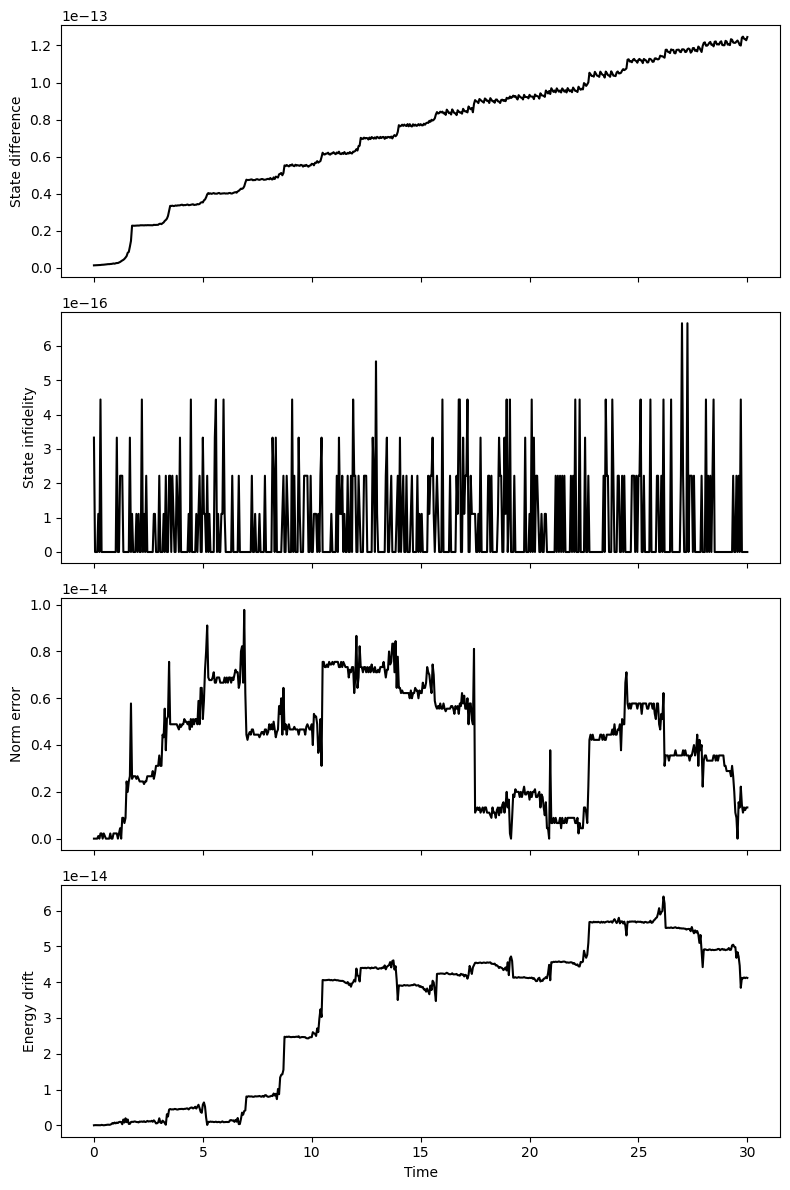

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True)

axes[0].plot(results["times"], results["state_differences"], color="black")
axes[0].set_ylabel("State difference")

axes[1].plot(results["times"], results["infidelities"], color="black")
axes[1].set_ylabel("State infidelity")

axes[2].plot(results["times"], results["norm_errors"], color="black")
axes[2].set_ylabel("Norm error")

axes[3].plot(results["times"], results["energy_errors"], color="black")
axes[3].set_ylabel("Energy drift")
axes[3].set_xlabel("Time")

plt.tight_layout()
plt.show()


In [ ]:
results = benchmarks.benchmark_revivals(H, initial_index, initial_time_step=0.05, refinements=8, tolerance=1e-3)

Time step: 0.05000000
Revival score: 0.83671643
Optimal period: 4.75

Time step: 0.02500000
Revival score: 0.83730579
Optimal period: 4.775
Score difference: 5.89361949e-04
Period difference: 2.50000000e-02
Score convergence criterion satisfied.

Time step: 0.01250000
Revival score: 0.83888977
Optimal period: 4.7625
Score difference: 1.58397804e-03
Period difference: 1.25000000e-02

Time step: 0.00625000
Revival score: 0.83888977
Optimal period: 4.7625
Score difference: 0.00000000e+00
Period difference: 0.00000000e+00
Score convergence criterion satisfied.

Time step: 0.00312500
Revival score: 0.83888977
Optimal period: 4.7625
Score difference: 0.00000000e+00
Period difference: 0.00000000e+00
Score convergence criterion satisfied.

Time step: 0.00156250
Revival score: 0.83889996
Optimal period: 4.7640625000000005
Score difference: 1.01881679e-05
Period difference: 1.56250000e-03
Score convergence criterion satisfied.

Time step: 0.00078125
Revival score: 0.83890223
Optimal period: 4.76

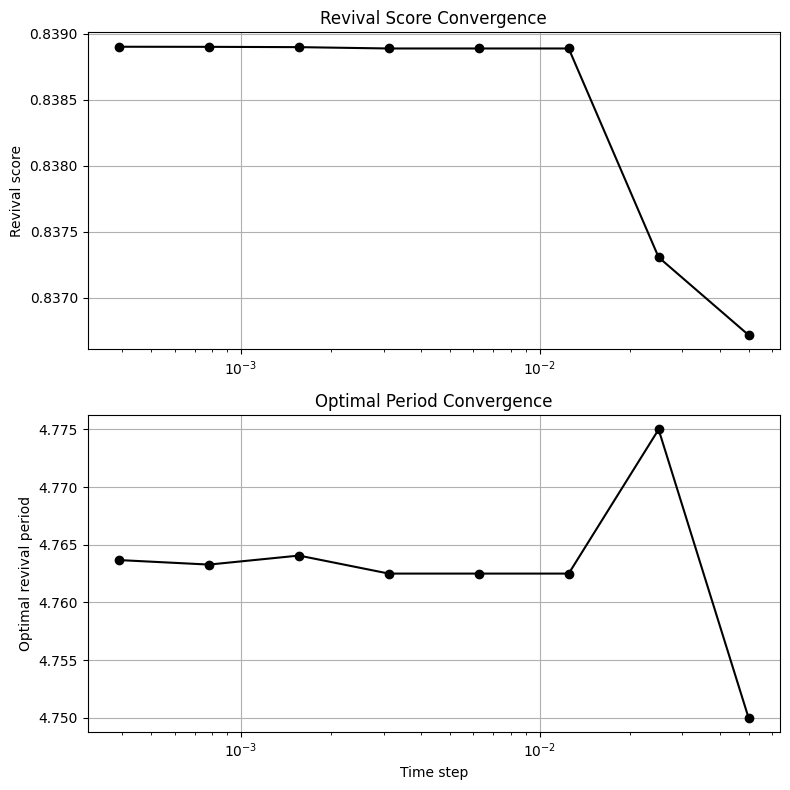

In [ ]:
time_steps = []
revival_scores = []
optimal_periods = []

for result in results:
    time_steps.append(result["time_step"])
    revival_scores.append(result["score"])
    optimal_periods.append(result["period"])


fig, axes = plt.subplots(2, 1, figsize=(8, 8))

axes[0].plot(time_steps, revival_scores, marker="o", linestyle="-", color="black")

axes[0].set_ylabel("Revival score")
axes[0].set_title("Revival Score Convergence")
axes[0].grid(True)
axes[0].set_xscale("log")

axes[1].plot(time_steps, optimal_periods, marker="o", linestyle="-", color="black")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Optimal revival period")
axes[1].set_title("Optimal Period Convergence")
axes[1].grid(True)
axes[1].set_xscale("log")

plt.tight_layout()
plt.show()

In [9]:
# Periodic chain, J = hbar = 1.
# All deformation parameters except lambda2 are zero.

L = 16

max_time = 30
initial_time_step = 0.05
refined_time_step = 0.025

state = pxp.basisStates(L)
indices = pxp.build_constrained_basis(L)

initial_bitstring = "10" * (L // 2)

full_initial_index = state.getIndex(initial_bitstring)
initial_index = indices.index(full_initial_index)

base_hamiltonian, deformation_hamiltonian = pxp.build_lambda2_components(state, indices)

In [10]:
lambda_values = np.linspace(-0.2, 0.2, 41)

scores, periods = evaluation.scan_lambda2(base_hamiltonian, deformation_hamiltonian, initial_index, lambda_values, time_step=initial_time_step, max_time=max_time)

best_index = np.argmax(scores)
best_lambda2 = lambda_values[best_index]

print("Initial scan")
print("Best lambda2:", best_lambda2)
print("Revival score:", scores[best_index])
print("Optimal period:", periods[best_index])

Initial scan
Best lambda2: 0.04999999999999999
Revival score: 0.9990948506851464
Optimal period: 4.95


In [11]:
refined_lambda_values = np.linspace(max(-0.2, best_lambda2 - 0.01), min(0.2, best_lambda2 + 0.01), 21)

refined_scores, refined_periods = evaluation.scan_lambda2(base_hamiltonian, deformation_hamiltonian, initial_index, refined_lambda_values, time_step=refined_time_step, max_time=max_time)

optimal_index = np.argmax(refined_scores)

optimal_lambda2 = refined_lambda_values[optimal_index]
optimal_score = refined_scores[optimal_index]
optimal_period = refined_periods[optimal_index]

print("Refined scan")
print("Best sampled lambda2:", optimal_lambda2)
print("Revival score:", optimal_score)
print("Optimal period:", optimal_period)

Refined scan
Best sampled lambda2: 0.04999999999999999
Revival score: 0.9990948506851458
Optimal period: 4.95


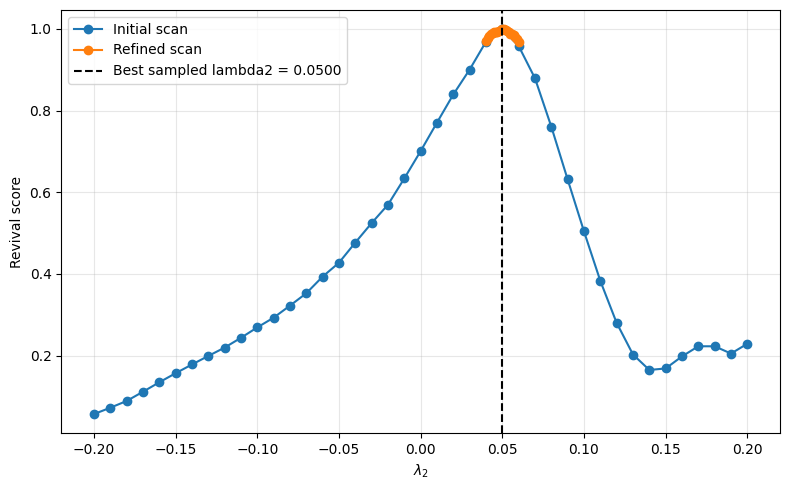

In [12]:
fig, axis = plt.subplots(figsize=(8, 5))

axis.plot(lambda_values, scores, "o-", label="Initial scan")

axis.plot(refined_lambda_values, refined_scores, "o-", label="Refined scan")

axis.axvline(optimal_lambda2, color="black", linestyle="--", label=f"Best sampled lambda2 = {optimal_lambda2:.4f}")

axis.set_xlabel(r"$\lambda_2$")
axis.set_ylabel("Revival score")

axis.legend()
axis.grid(alpha=0.3)

fig.tight_layout()
plt.show()

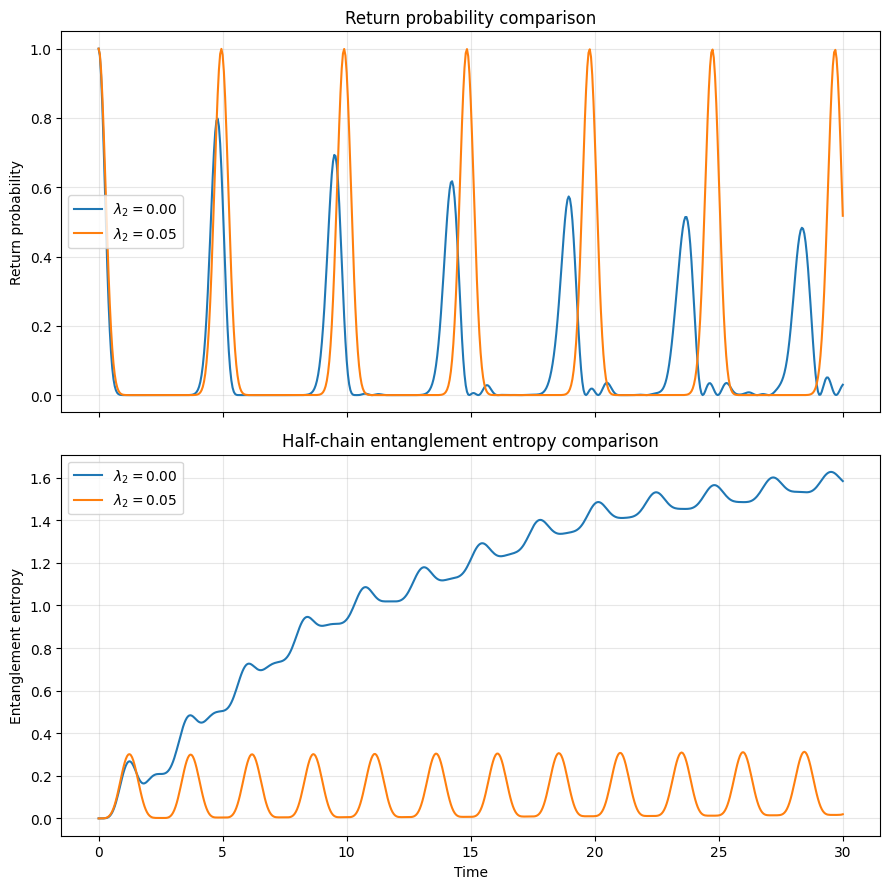

In [13]:
lambda_values_comparison = [0.0, 0.05]

fig, axes = plt.subplots(2, 1, figsize=(9, 9), sharex=True)

for lambda2 in lambda_values_comparison:
    H = pxp.assemble_lambda2_hamiltonian(base_hamiltonian, deformation_hamiltonian, lambda2)

    times, evolved_states = dynamics.time_evolution(H, initial_index, time_step=initial_time_step, max_time=max_time)

    probabilities = observables.return_probability(evolved_states, initial_index)

    entropies = observables.entanglement_entropy(evolved_states, state, indices)

    axes[0].plot(times, probabilities, label=fr"$\lambda_2 = {lambda2:.2f}$")

    axes[1].plot(times, entropies, label=fr"$\lambda_2 = {lambda2:.2f}$")

axes[0].set_ylabel("Return probability")
axes[0].set_title("Return probability comparison")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_xlabel("Time")
axes[1].set_ylabel("Entanglement entropy")
axes[1].set_title("Half-chain entanglement entropy comparison")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

L =  8, dimension =    47, first revival = 4.950
L = 10, dimension =   123, first revival = 4.950
L = 12, dimension =   322, first revival = 4.950
L = 14, dimension =   843, first revival = 4.950
L = 16, dimension =  2207, first revival = 4.950
L = 18, dimension =  5778, first revival = 4.950


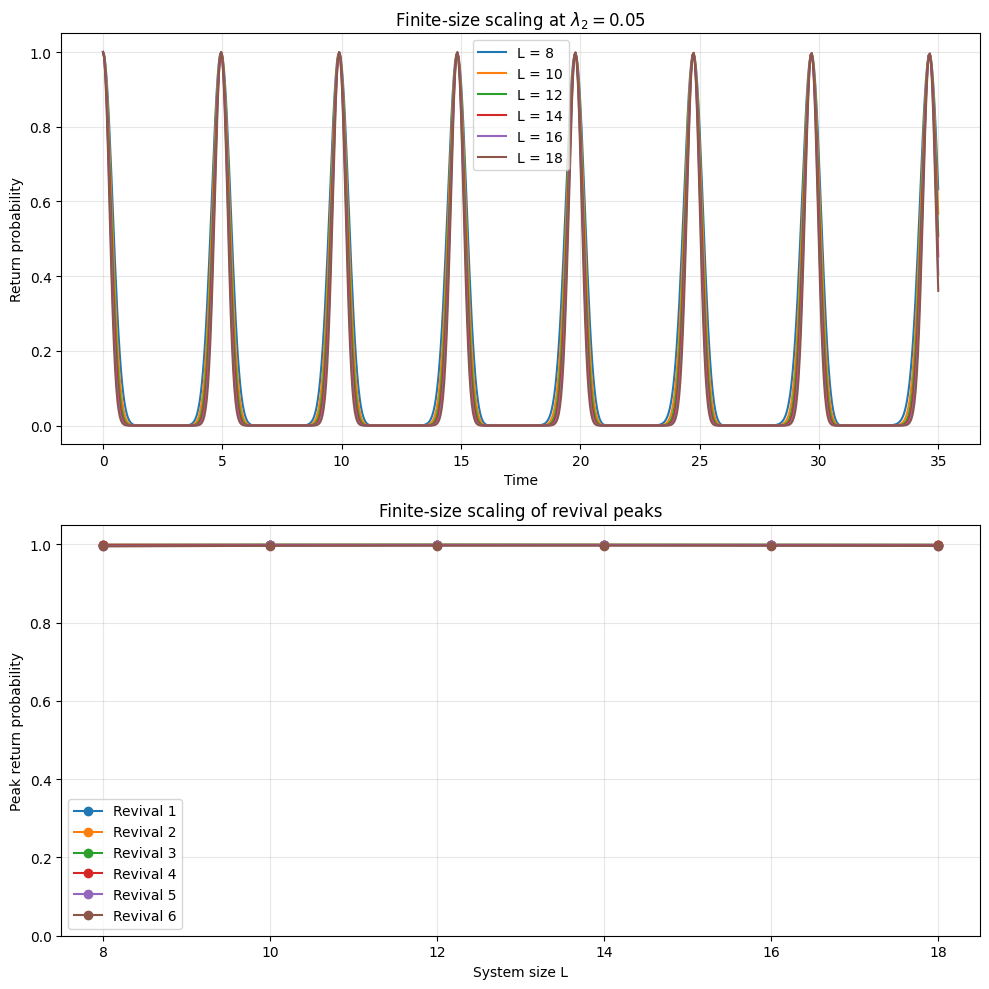

In [ ]:
system_sizes = [8, 10, 12, 14, 16, 18]

lambda2 = 0.05
time_step = 0.05
max_time = 35

revival_numbers = np.arange(1, 7)
revival_peaks = np.zeros((len(system_sizes), len(revival_numbers)))

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

for position, L in enumerate(system_sizes):
    state = pxp.basisStates(L)
    indices = pxp.build_constrained_basis(L)

    initial_bitstring = "10" * (L // 2)
    full_initial_index = state.getIndex(initial_bitstring)
    initial_index = indices.index(full_initial_index)

    base_hamiltonian, deformation_hamiltonian = pxp.build_lambda2_components(state, indices)

    H = pxp.assemble_lambda2_hamiltonian(base_hamiltonian, deformation_hamiltonian, lambda2)

    times, evolved_states = dynamics.time_evolution(H, initial_index, time_step=time_step, max_time=max_time)

    probabilities = observables.return_probability(evolved_states, initial_index)

    # Estimate the first revival period
    first_window = (times >= 3) & (times <= 7)

    first_revival_time = times[first_window][np.argmax(probabilities[first_window])]

    # Find the maximum probability near each expected revival
    for revival_position, revival_number in enumerate(revival_numbers):
        expected_time = revival_number * first_revival_time

        window = ((times >= expected_time - 0.75) & (times <= expected_time + 0.75))

        revival_peaks[position, revival_position] = np.max(probabilities[window])

    axes[0].plot(times, probabilities, label=f"L = {L}")

    print(f"L = {L:2d}, dimension = {H.shape[0]:5d}, "f"first revival = {first_revival_time:.3f}")

    del evolved_states


axes[0].set_xlabel("Time")
axes[0].set_ylabel("Return probability")
axes[0].set_title(r"Finite-size scaling at $\lambda_2 = 0.05$")
axes[0].legend()
axes[0].grid(alpha=0.3)


for revival_position, revival_number in enumerate(revival_numbers):
    axes[1].plot(system_sizes, revival_peaks[:, revival_position], marker="o", label=f"Revival {revival_number}")

axes[1].set_xlabel("System size L")
axes[1].set_ylabel("Peak return probability")
axes[1].set_title("Finite-size scaling of revival peaks")
axes[1].set_ylim(0, 1.05)
axes[1].set_xticks(system_sizes)
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()



L = 8
Revival 1: P = 0.9994464318, 1 - P = 5.535682e-04
Revival 2: P = 0.9993736737, 1 - P = 6.263263e-04
Revival 3: P = 0.9983504582, 1 - P = 1.649542e-03
Revival 4: P = 0.9976752953, 1 - P = 2.324705e-03
Revival 5: P = 0.9960091577, 1 - P = 3.990842e-03
Revival 6: P = 0.9948603537, 1 - P = 5.139646e-03

L = 10
Revival 1: P = 0.9995736266, 1 - P = 4.263734e-04
Revival 2: P = 0.9992690257, 1 - P = 7.309743e-04
Revival 3: P = 0.9988191042, 1 - P = 1.180896e-03
Revival 4: P = 0.9981108275, 1 - P = 1.889173e-03
Revival 5: P = 0.9973694059, 1 - P = 2.630594e-03
Revival 6: P = 0.9963693173, 1 - P = 3.630683e-03

L = 12
Revival 1: P = 0.9995586189, 1 - P = 4.413811e-04
Revival 2: P = 0.9993047582, 1 - P = 6.952418e-04
Revival 3: P = 0.9990312439, 1 - P = 9.687561e-04
Revival 4: P = 0.9984240423, 1 - P = 1.575958e-03
Revival 5: P = 0.9976538329, 1 - P = 2.346167e-03
Revival 6: P = 0.9967638485, 1 - P = 3.236151e-03

L = 14
Revival 1: P = 0.9994394336, 1 - P = 5.605664e-04
Revival 2: P = 0.99

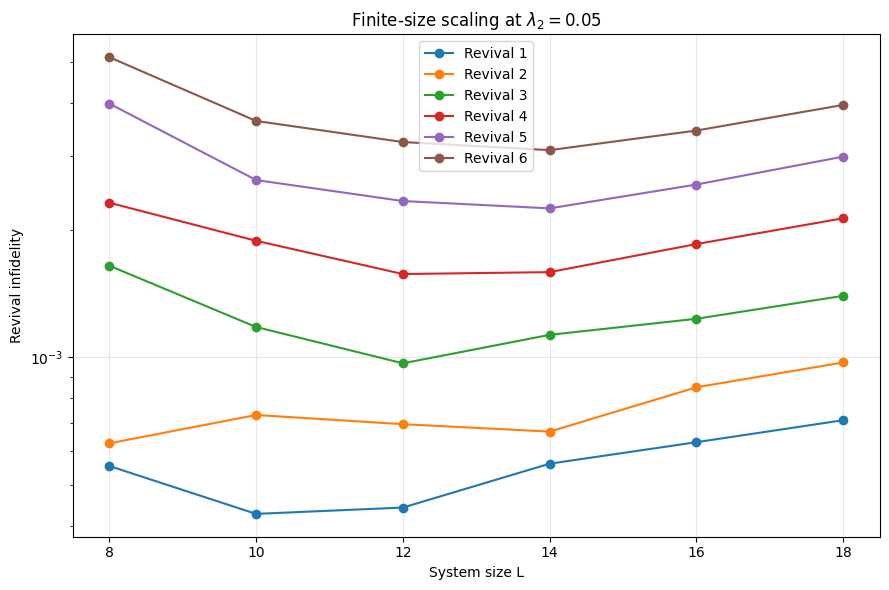

In [ ]:
revival_infidelities = 1 - revival_peaks

for position, L in enumerate(system_sizes):
    print(f"\nL = {L}")

    for revival_position, revival_number in enumerate(revival_numbers):
        print(
            f"Revival {revival_number}: "
            f"P = {revival_peaks[position, revival_position]:.10f}, "
            f"1 - P = {revival_infidelities[position, revival_position]:.6e}"
        )

fig, axis = plt.subplots(figsize=(9, 6))

for revival_position, revival_number in enumerate(revival_numbers):
    axis.semilogy(system_sizes, revival_infidelities[:, revival_position], marker="o", label=f"Revival {revival_number}")

axis.set_xlabel("System size L")
axis.set_ylabel("Revival infidelity")
axis.set_title(r"Finite-size scaling at $\lambda_2 = 0.05$")
axis.set_xticks(system_sizes)
axis.legend()
axis.grid(alpha=0.3)

fig.tight_layout()
plt.show()